# Explainable Models: Permutation Importance, Partial Dependence and Their Limits

**Dataset:** `auto_mpg` | **Level:** advanced

Explain a gradient boosting model on fuel efficiency and test whether the explanation is stable.

Sections: 1 Problem, 2 Method, 3 Setup and data, 4 Experiment, 5 Results, 6 Interpretation, 7 Limitations, 8 Exercises, 9 References.

## 1. Problem

A tree ensemble predicts mpg well but has no coefficients. We need global explanations and a check that they do not change with the random seed or the data sample.

## 2. Method

Permutation importance on held out rows (drop in R2 when one column is shuffled), partial dependence for the top feature, and a stability check over 20 bootstrap fits. No SHAP library is used because it was not available in the build environment.

## 3. Setup and data

Auto MPG, 392 rows, 7 features (see `datasets/catalog/supervised.json`).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score
from ml_lab.data import load_dataset
from ml_lab.preprocessing import split_three_way, make_model_pipeline
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz
NB_ID = "explainable_ai"
SEED = 42
set_seed(SEED); viz.apply_style(); print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
b = load_dataset("auto_mpg"); X, y = b.X, b.y
Xtr, Xva, Xte, ytr, yva, yte = split_three_way(X, y, task="regression", seed=SEED)
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import r2_score
Xtv, ytv = pd.concat([Xtr, Xva]), pd.concat([ytr, yva])
model = make_model_pipeline(Xtv, HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED), scale=False).fit(Xtv, ytv)
print("test R2:", round(r2_score(yte, model.predict(Xte)), 3))

test R2: 0.887


## 4. Experiment

Permutation importance on the test rows, 20 repeats.

In [3]:
imp = permutation_importance(model, Xte, yte, scoring="r2", n_repeats=20, random_state=SEED)
tab = pd.DataFrame({"importance": imp.importances_mean, "std": imp.importances_std}, index=X.columns).sort_values("importance", ascending=False)
display(tab.round(3))

,importance,std
weight,0.311,0.059
model_year,0.306,0.060
displacement,0.081,0.022
horsepower,0.064,0.021
acceleration,0.016,0.006
origin,0.011,0.004
cylinders,0.003,0.004


## 5. Results

Partial dependence of the top feature, and rank stability over 20 bootstrap refits of the whole model.

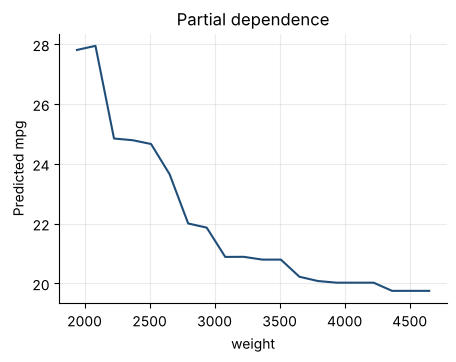

,mean,std
weight,1.60,0.88
model_year,1.95,0.39
displacement,3.40,1.73
horsepower,3.60,0.75
acceleration,5.10,0.72
cylinders,5.95,1.32
origin,6.40,0.60


saved: experiments/results/explainable_ai.json


In [4]:
top = tab.index[0]
pdp = partial_dependence(model, Xte, [top], grid_resolution=20)
fig, ax = plt.subplots(figsize=(5, 3.5)); ax.plot(pdp["grid_values"][0], pdp["average"][0]); ax.set_xlabel(top); ax.set_ylabel("Predicted mpg"); ax.set_title("Partial dependence"); save_figure(fig, NB_ID, "pdp"); plt.show()
ranks = []
rng = np.random.default_rng(SEED)
for _ in range(20):
    i = rng.integers(0, len(Xtv), len(Xtv))
    m = make_model_pipeline(Xtv.iloc[i], HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200, random_state=int(rng.integers(1e6))), scale=False).fit(Xtv.iloc[i], ytv.iloc[i])
    pi = permutation_importance(m, Xte, yte, scoring="r2", n_repeats=5, random_state=0).importances_mean
    ranks.append(pd.Series(pi, index=X.columns).rank(ascending=False))
rank_tab = pd.DataFrame(ranks).agg(["mean", "std"]).T.sort_values("mean"); display(rank_tab.round(2))
METRICS = {"test_R2": float(r2_score(yte, model.predict(Xte))), "top_feature_importance": float(tab.iloc[0]["importance"]), "top_feature_rank_std": float(rank_tab.loc[top, "std"]), "n_bootstrap": 20.0}
CONFIG = {"model": "HistGradientBoostingRegressor", "repeats": 20}; EXTRA = {"importance": tab.round(4).reset_index().to_dict("records"), "top_feature": top}; ALGORITHM = "permutation importance, PDP"

record = ExperimentRecord(notebook=NB_ID, family="advanced", algorithm=ALGORITHM, dataset="auto_mpg", task="regression", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())

## 6. Interpretation

A feature with a large importance and a small rank standard deviation is a reliable driver. Features whose rank moves a lot (large std) are correlated with others (weight, displacement, horsepower), so importance is shared between them and should not be read one by one.

## 7. Limitations

Permutation importance treats correlated features as independent, which can create unrealistic rows. Partial dependence averages over such rows. Both describe the model, not causal effects.

## 8. Exercises

1. Group correlated features and permute them together.
2. Add individual conditional expectation curves.
3. Install SHAP and compare its ranking with permutation importance.

## 9. References

Breiman (2001) `breiman2001` introduced permutation importance for forests. Friedman (2001) `friedman2001` introduced partial dependence plots. Both are in `research/source-register.md`.